# push_t_book_2 — world-model "video game" + imagined rollouts

Book versions of the P69–P71 visuals from `p69_73.ipynb`:

- **A. Four-direction test** — from episode `EPISODE_ID` t=0, push the LeWM predictor one action block
  (5 steps) left / right / up / down, decode each predicted embedding, and lay the results out as a cross.
- **B. Imagined rollouts** — replay the expert actions of the same episode through (1) the real env and
  (2) the world model, and render both as vertical strips, every 5 steps.

Rendering:
- **Real frames** are vector-rendered from the env state (same renderer as `push_t_book_1`).
- **Decoded world-model frames** are rasters, so they go through `recolor_pusht` (Gaussian soft-min over
  hand-sampled source anchors) with the target colors taken from the same `PALETTE`.


## 1. Config

In [1]:
from pathlib import Path

# ── Print palette ──────────────────────────────────────────────────────────
CHILL_BROWN = "#948678"
LT_BLUE     = "#5badb6"
ORANGE      = "#eb8423"
FRESH_TAN   = "#f4ebd9"

PALETTE = dict(
    target      = CHILL_BROWN,   # goal / target T
    movable     = LT_BLUE,       # the T being pushed
    effector    = ORANGE,        # the circular pusher
    background  = FRESH_TAN,
    outline     = None,          # vector shapes only; None = flat fills
    frame       = CHILL_BROWN,   # box around each frame; None = no box
    frame_width = 1.5,           # stroke width of that box, in points
)

# ── Episode / model ────────────────────────────────────────────────────────
EPISODE_ID    = 18002      # human episode used for both the 4-direction test and the rollouts
ACTION_MAG    = 0.15       # env-scale magnitude of the single-direction test actions
RECOLOR_SIGMA = 45.0       # softness of the decoded-frame recolor (12 crisp … 45 soft)
HISTORY_SIZE  = 3          # predictor context length (action blocks)

# ── Rollout strips ─────────────────────────────────────────────────────────
ROLLOUT_STRIDE = 5         # must be a multiple of 5 (the model's action block)
MAX_FRAMES     = None      # cap on frames per strip (None = whole episode)
WM_T0          = "decoded" # "decoded": t=0 of the WM strip is the decoded real start
                           # "real":    t=0 of the WM strip is the vector-rendered real start

# ── Paths ──────────────────────────────────────────────────────────────────
# HACKIN   = Path("/Users/stephen/Library/CloudStorage/Dropbox-Stephencwelch/welch_labs/jepa_2/hackin")
HACKIN   = Path("/home/stephen/Stephencwelch Dropbox/welch_labs/jepa_2/hackin")

LEWM_DIR = HACKIN / "le-wm"                       # decoder.py, decoder_mc_10_epochs.pt, adapter_weights.pt
OUT_ROOT = HACKIN / "push_t_book_2"
OUT_DIR  = Path("/home/stephen/Stephencwelch Dropbox/welch_labs/ai_book_vol_2/4_jepa/graphics") / f"ep_{EPISODE_ID:05d}"

# ── Labels on strips ───────────────────────────────────────────────────────
LABEL_FONT  = "Helvetica"
LABEL_SIZE  = 9
LABEL_COLOR = CHILL_BROWN
LABEL_INSET = 14           # world px from the frame edges
LABEL_FMT   = "{t}"

import matplotlib.pyplot as plt
plt.rcParams["svg.fonttype"] = "none"   # keep text editable in Illustrator


## 2. Setup — env, dataset, model, decoder

In [2]:
import warnings, sys
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import scipy.ndimage as ndi
import torch, torch.nn as nn
import gymnasium as gym
from matplotlib.patches import Polygon, Circle, Rectangle
from PIL import Image
from sklearn.preprocessing import StandardScaler
from torchvision.transforms import v2 as transforms

# import stable_pretraining as spt
import stable_worldmodel as swm

sys.path.append(str(LEWM_DIR))
from decoder import CLSDecoder

DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print("device:", DEVICE)

# dataset + action scaler
ds = swm.data.HDF5Dataset(name="pusht_expert_train", keys_to_cache=["action", "state"])
ep_lens   = np.asarray(ds.lengths, dtype=np.int64)
ep_starts = np.concatenate([[0], np.cumsum(ep_lens)[:-1]])

all_actions = ds.get_col_data("action")
if all_actions.ndim == 3:
    all_actions = all_actions.reshape(-1, all_actions.shape[-1])
all_actions = all_actions[~np.isnan(all_actions).any(axis=1)]
action_scaler = StandardScaler().fit(all_actions)

# encoder / predictor
IMG_SIZE = 224
img_transform = transforms.Compose([
    transforms.ToImage(),
    transforms.ToDtype(torch.float32, scale=True),
    # transforms.Normalize(**spt.data.dataset_stats.ImageNet),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    transforms.Resize(size=IMG_SIZE),
])
cost_model = swm.policy.AutoCostModel("pusht/lewm").to(DEVICE).eval()
cost_model.requires_grad_(False)
cost_model.interpolate_pos_encoding = True

# CLS decoder + adapter (Matthew's weights)
decoder_mc = CLSDecoder(cls_dim=192, img_size=224, patch_size=14, dim=256, heads=8, depth=3)
decoder_mc.load_state_dict(torch.load(LEWM_DIR / "decoder_mc_10_epochs.pt", weights_only=True,
                                      map_location="cpu"), strict=False)
decoder_mc = decoder_mc.to(DEVICE).eval(); decoder_mc.requires_grad_(False)

enc_dim, proj_dim = cost_model.encoder.config.hidden_size, 192
adapter = nn.Sequential(nn.Linear(proj_dim, 512), nn.GELU(), nn.Linear(512, enc_dim))
adapter.load_state_dict(torch.load(LEWM_DIR / "adapter_weights.pt", weights_only=True,
                                   map_location="cpu"), strict=False)
adapter = adapter.to(DEVICE).eval(); adapter.requires_grad_(False)
print("models loaded")


device: cuda
models loaded


In [3]:
# ── world-model helpers (from p69_73) ──────────────────────────────────────
@torch.no_grad()
def encode_frame(rgb_uint8):
    """(H, W, 3) uint8 -> (1, D) projected embedding."""
    px = img_transform(rgb_uint8).unsqueeze(0).unsqueeze(0).to(DEVICE)
    return cost_model.encode({"pixels": px})["emb"][:, 0]

@torch.no_grad()
def decode_emb(emb):
    """(1, D) projected embedding -> (224, 224, 3) uint8 decoded image."""
    img = decoder_mc(adapter(emb))[0].permute(1, 2, 0).cpu().numpy()
    img = (img - img.min()) / (img.max() - img.min() + 1e-8)
    return np.round(img * 255).astype(np.uint8)

def pack_action_block(a5x2):
    """(5, 2) env-scale actions -> (1, 10) standardized tensor."""
    a = np.asarray(a5x2, dtype=np.float32); assert a.shape == (5, 2)
    return torch.from_numpy(action_scaler.transform(a).astype(np.float32).reshape(-1)).to(DEVICE).unsqueeze(0)

@torch.no_grad()
def predict_next(emb_hist, act_hist, history_size=HISTORY_SIZE):
    emb_seq = torch.stack(emb_hist[-history_size:], dim=1)
    act_seq = torch.stack(act_hist[-history_size:], dim=1)
    return cost_model.predict(emb_seq, cost_model.action_encoder(act_seq))[:, -1]

def imagine(first_emb, action_blocks):
    """Roll the predictor forward over a list of (5, 2) env-scale action blocks.
    Returns list of (1, D) embeddings, starting with first_emb."""
    emb_hist, act_hist = [first_emb], []
    for a5 in action_blocks:
        act_hist.append(pack_action_block(a5))
        emb_hist.append(predict_next(emb_hist, act_hist))
    return emb_hist


## 3. Rendering — vector (real) and recolor (decoded)

In [4]:
# ── PushT geometry (from stable_worldmodel/envs/pusht/env.py) ──────────────
WORLD        = 512
GOAL_POSE    = np.array([256.0, 256.0, np.pi / 4])
AGENT_RADIUS = 0.375 * 40
_S, _L = 30, 120                         # tee: scale 30, length 4
_T_OUTLINE = np.array([(-_L/2, 0), (_L/2, 0), (_L/2, _S), (_S/2, _S), (_S/2, _L),
                       (-_S/2, _L), (-_S/2, _S), (-_L/2, _S)], float)

def tee_world_vertices(x, y, angle):
    c, s = np.cos(angle), np.sin(angle)
    return (_T_OUTLINE @ np.array([[c, -s], [s, c]]).T) + (x, y)

def draw_tee(ax, pose, color, outline=None, zorder=1):
    ax.add_patch(Polygon(tee_world_vertices(*pose), closed=True, facecolor=color,
                         edgecolor=outline if outline else color,
                         linewidth=0.8 if outline else 0, joinstyle="miter", zorder=zorder))

def _finish_axes(ax, palette):
    """Background square + frame box + limits; shared by both renderers."""
    ax.patch.set_alpha(0)
    ax.add_patch(Rectangle((0, 0), WORLD, WORLD, facecolor=palette["background"],
                           edgecolor="none", zorder=0))
    if palette.get("frame"):
        ax.add_patch(Rectangle((0, 0), WORLD, WORLD, facecolor="none",
                               edgecolor=palette["frame"], linewidth=palette.get("frame_width", 1.5),
                               joinstyle="miter", clip_on=False, zorder=10))
    ax.set_xlim(0, WORLD); ax.set_ylim(WORLD, 0); ax.set_aspect("equal"); ax.axis("off")

def render_state(state, ax, palette=PALETTE, show_goal=True):
    """Vector frame from a 7-d env state."""
    _finish_axes(ax, palette)
    if show_goal:
        draw_tee(ax, GOAL_POSE, palette["target"], palette["outline"], zorder=1)
    draw_tee(ax, (state[2], state[3], state[4]), palette["movable"], palette["outline"], zorder=2)
    ax.add_patch(Circle((state[0], state[1]), AGENT_RADIUS, facecolor=palette["effector"],
                        edgecolor=palette["outline"] if palette["outline"] else palette["effector"],
                        linewidth=0.8 if palette["outline"] else 0, zorder=3))
    return ax

def render_pixels(img_uint8, ax, palette=PALETTE):
    """Raster frame (already recolored) placed in the same 512-world coordinates."""
    _finish_axes(ax, palette)
    ax.imshow(img_uint8, extent=(0, WORLD, WORLD, 0), interpolation="bilinear", zorder=1)
    return ax

def render_item(item, ax, palette=PALETTE):
    """Dispatch: 1-d array = env state (vector), 3-d array = image (raster)."""
    item = np.asarray(item)
    return render_state(item, ax, palette) if item.ndim == 1 else render_pixels(item, ax, palette)

def add_step_label(ax, t):
    ax.text(WORLD - LABEL_INSET, WORLD - LABEL_INSET, LABEL_FMT.format(t=t),
            fontfamily=[LABEL_FONT, "DejaVu Sans"], fontweight="bold", fontsize=LABEL_SIZE,
            color=LABEL_COLOR, ha="right", va="bottom", zorder=11)


In [5]:
# ── recolor for decoded (raster) frames ────────────────────────────────────
def _hex(h):
    h = h.lstrip("#"); return np.array([int(h[i:i+2], 16) for i in (0, 2, 4)], dtype=np.float32)

def make_recolor_palette(src, palette=PALETTE):
    """Combine hand-sampled source anchors with the print palette as targets."""
    p = dict(src)
    p.update({
        "tgt_bg":               _hex(palette["background"]),
        "tgt_frame_border":     _hex(palette["background"]),   # border folds into background
        "tgt_target_fill":      _hex(palette["target"]),
        "tgt_target_outline":   _hex(palette["target"]),
        "tgt_movable_fill":     _hex(palette["movable"]),
        "tgt_movable_outline":  _hex(palette["movable"]),
        "tgt_effector_fill":    _hex(palette["effector"]),
        "tgt_effector_outline": _hex(palette["effector"]),
    })
    return p

# source anchors sampled from the *decoder* output (from p69_73 DECODED_PALETTE)
DECODED_SRC = {
    "src_bg":               np.array([203, 214, 226], dtype=np.float32),
    "src_frame_border":     np.array([156, 164, 178], dtype=np.float32),
    "src_target_fill":      np.array([ 88, 201, 112], dtype=np.float32),
    "src_movable_fill":     np.array([ 92, 121, 147], dtype=np.float32),
    "src_effector_fill":    np.array([ 15,  69, 215], dtype=np.float32),
    "src_target_outline":   np.array([ 87, 172, 115], dtype=np.float32),
    "src_movable_outline":  np.array([ 53,  77, 103], dtype=np.float32),
    "src_effector_outline": np.array([ 14,  61, 175], dtype=np.float32),
    "r_target_fill": 45.0, "r_movable_fill": 22.0, "r_effector_fill": 55.0,
    "min_component_size": 10,
}
DECODED_PALETTE = make_recolor_palette(DECODED_SRC)

_SHAPES = [
    (1, "src_target_fill",   "src_target_outline",   "tgt_target_fill",   "tgt_target_outline"),
    (2, "src_movable_fill",  "src_movable_outline",  "tgt_movable_fill",  "tgt_movable_outline"),
    (3, "src_effector_fill", "src_effector_outline", "tgt_effector_fill", "tgt_effector_outline"),
]

def _keep_largest_components(mask, min_size):
    lab, n = ndi.label(mask)
    if n == 0: return mask
    sizes = ndi.sum_labels(mask, lab, range(1, n + 1))
    keep = np.zeros(n + 1, dtype=bool); keep[1:] = sizes >= min_size
    return keep[lab]

def _segment_shapes(img, p):
    ball = lambda anchor, r: np.linalg.norm(img - anchor, axis=-1) < r
    m = int(p["min_component_size"])
    labels = np.zeros(img.shape[:2], dtype=np.int32)
    labels[_keep_largest_components(ball(p["src_target_fill"],   p["r_target_fill"]),   m)] = 1
    labels[_keep_largest_components(ball(p["src_movable_fill"],  p["r_movable_fill"]),  m)] = 2
    labels[_keep_largest_components(ball(p["src_effector_fill"], p["r_effector_fill"]), m)] = 3
    if (labels == 0).all(): return labels
    _, idx = ndi.distance_transform_edt(labels == 0, return_indices=True)
    return labels[idx[0], idx[1]]

def recolor_pusht(frame, palette=None, sigma=RECOLOR_SIGMA):
    """Recolor one (H, W, 3) uint8 PushT-like frame via Gaussian soft-min over anchors."""
    p = palette if palette is not None else DECODED_PALETTE
    img = frame.astype(np.float32)
    lbl = _segment_shapes(img, p)
    src_fill, src_out = np.empty_like(img), np.empty_like(img)
    tgt_fill, tgt_out = np.empty_like(img), np.empty_like(img)
    for v, sf, so, tf, to in _SHAPES:
        m = lbl == v
        if m.any():
            src_fill[m], src_out[m], tgt_fill[m], tgt_out[m] = p[sf], p[so], p[tf], p[to]
    if (lbl == 0).any():
        m = lbl == 0
        src_fill[m] = src_out[m] = p["src_bg"]; tgt_fill[m] = tgt_out[m] = p["tgt_bg"]
    src = np.stack([src_fill, src_out, np.broadcast_to(p["src_bg"], img.shape),
                    np.broadcast_to(p["src_frame_border"], img.shape)], axis=-2)
    tgt = np.stack([tgt_fill, tgt_out, np.broadcast_to(p["tgt_bg"], img.shape),
                    np.broadcast_to(p["tgt_frame_border"], img.shape)], axis=-2)
    w = np.exp(-((img[..., None, :] - src) ** 2).sum(-1) / (2 * sigma * sigma))
    w /= w.sum(-1, keepdims=True)
    return np.clip((w[..., None] * tgt).sum(-2), 0, 255).astype(np.uint8)

def decode_recolored(emb):
    return recolor_pusht(decode_emb(emb))


## 4. Load the episode and the real start frame

episode 18002: length 89   init_state [211.  441.  417.9 214.1   2.2   0.    0. ]


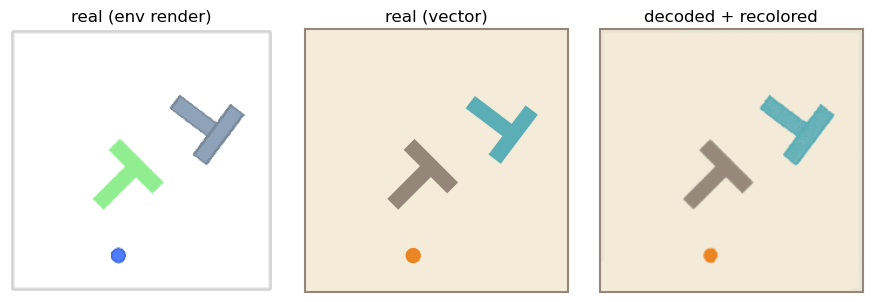

In [6]:
ep_len = int(ep_lens[EPISODE_ID]); row0 = int(ep_starts[EPISODE_ID])
actions_env = np.stack([ds[row0 + t]["action"].squeeze(0).cpu().numpy() for t in range(ep_len)]).astype(np.float32)
init_state  = ds[row0]["state"].squeeze(0).cpu().numpy().astype(np.float32)
print(f"episode {EPISODE_ID}: length {ep_len}   init_state {init_state.round(1)}")

env_play = gym.make("swm/PushT-v1", render_mode="rgb_array", max_episode_steps=ep_len + 10)
env_play.reset(seed=0)
env_play.unwrapped._set_state(state=init_state)
start_frame_real = env_play.render()                 # (224, 224, 3) uint8, original colors
start_state_real = env_play.unwrapped._get_obs()     # (7,) — what the env actually holds after _set_state
first_emb        = encode_frame(start_frame_real)    # (1, D)

# decoded version of the encoded start: a gut check on adapter + decoder + recolor
start_decoded = decode_recolored(first_emb)

fig, axs = plt.subplots(1, 3, figsize=(9, 3))
axs[0].imshow(start_frame_real); axs[0].set_title("real (env render)"); axs[0].axis("off")
render_state(start_state_real, axs[1]); axs[1].set_title("real (vector)")
render_pixels(start_decoded, axs[2]);   axs[2].set_title("decoded + recolored")
plt.tight_layout(); plt.show()


## A. Four-direction test

One action block (5 identical steps of magnitude `ACTION_MAG`) in each direction from the same start,
each predicted independently (fresh history every time), decoded, and recolored.

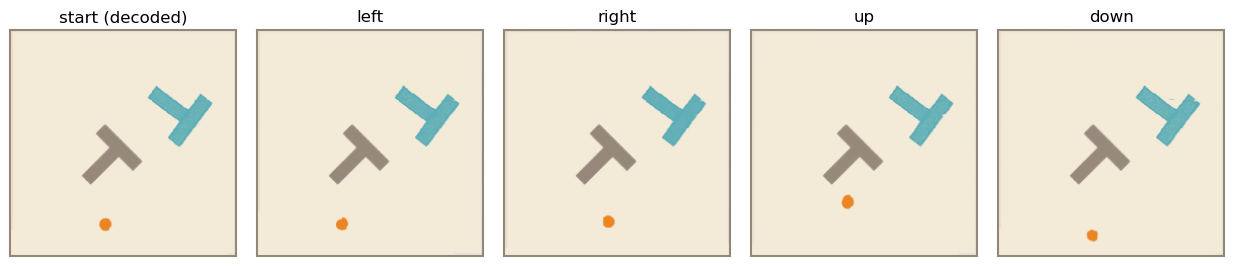

In [7]:
DIRECTIONS = {               # env action convention: +x right, +y down
    "left":  (-ACTION_MAG, 0.0),
    "right": ( ACTION_MAG, 0.0),
    "up":    (0.0, -ACTION_MAG),
    "down":  (0.0,  ACTION_MAG),
}

dir_frames, dir_embs = {}, {}
for name, (dx, dy) in DIRECTIONS.items():
    a5 = np.tile([[dx, dy]], (5, 1)).astype(np.float32)
    emb_hist = imagine(first_emb, [a5])
    dir_embs[name]   = emb_hist[-1]
    dir_frames[name] = decode_recolored(emb_hist[-1])

fig, axs = plt.subplots(1, 5, figsize=(12.5, 2.6))
render_pixels(start_decoded, axs[0]); axs[0].set_title("start (decoded)")
for ax, name in zip(axs[1:], DIRECTIONS):
    render_pixels(dir_frames[name], ax); ax.set_title(name)
plt.tight_layout(); plt.show()


### Cross layout → SVG
Start frame in the middle, the four predictions around it. Gaps are transparent; each frame carries its
own background square and box. `CROSS_CENTER` picks whether the center is the decoded start (same
pipeline as the arms) or the real start, vector-rendered.

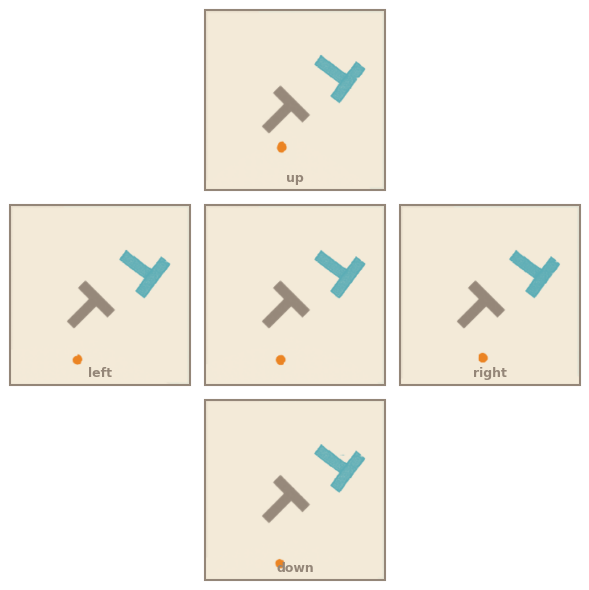

saved /home/stephen/Stephencwelch Dropbox/welch_labs/ai_book_vol_2/4_jepa/graphics/ep_18002/four_directions_cross.svg


In [8]:
CROSS_FRAME_SIZE = 1.8     # inches per frame
CROSS_GAP        = 0.15    # inches between frames
CROSS_CENTER     = "decoded"   # "decoded" | "real"
CROSS_LABELS     = True        # direction name under/over each arm

center_item = start_decoded if CROSS_CENTER == "decoded" else start_state_real
grid = {(1, 1): ("start", center_item), (0, 1): ("up", dir_frames["up"]),
        (2, 1): ("down", dir_frames["down"]), (1, 0): ("left", dir_frames["left"]),
        (1, 2): ("right", dir_frames["right"])}

cell = CROSS_FRAME_SIZE + CROSS_GAP
fig = plt.figure(figsize=(3 * cell - CROSS_GAP, 3 * cell - CROSS_GAP))
fig.patch.set_alpha(0)
W = H = 3 * cell - CROSS_GAP
for (r, c), (name, item) in grid.items():
    ax = fig.add_axes([c * cell / W, 1 - (r + 1) * cell / H + CROSS_GAP / H,
                       CROSS_FRAME_SIZE / W, CROSS_FRAME_SIZE / H])
    render_item(item, ax)
    if CROSS_LABELS and name != "start":
        ax.text(WORLD / 2, WORLD - LABEL_INSET, name, fontfamily=[LABEL_FONT, "DejaVu Sans"],
                fontweight="bold", fontsize=LABEL_SIZE, color=LABEL_COLOR,
                ha="center", va="bottom", zorder=11)

OUT_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(OUT_DIR / "four_directions_cross.svg", transparent=True, bbox_inches="tight", pad_inches=0.02)
for name, item in [("start_decoded", start_decoded)] + list(dir_frames.items()):
    Image.fromarray(item).save(OUT_DIR / f"dir_{name}.png")
plt.show()
print("saved", OUT_DIR / "four_directions_cross.svg")


## B. Imagined rollouts

Replay the episode's expert actions through the real env (recording states → vector frames) and through
the world model in 5-step blocks (decoded + recolored frames). Both sampled every `ROLLOUT_STRIDE` steps.

18 frames at steps [0, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60, 65, 70, 75, 80, 85]


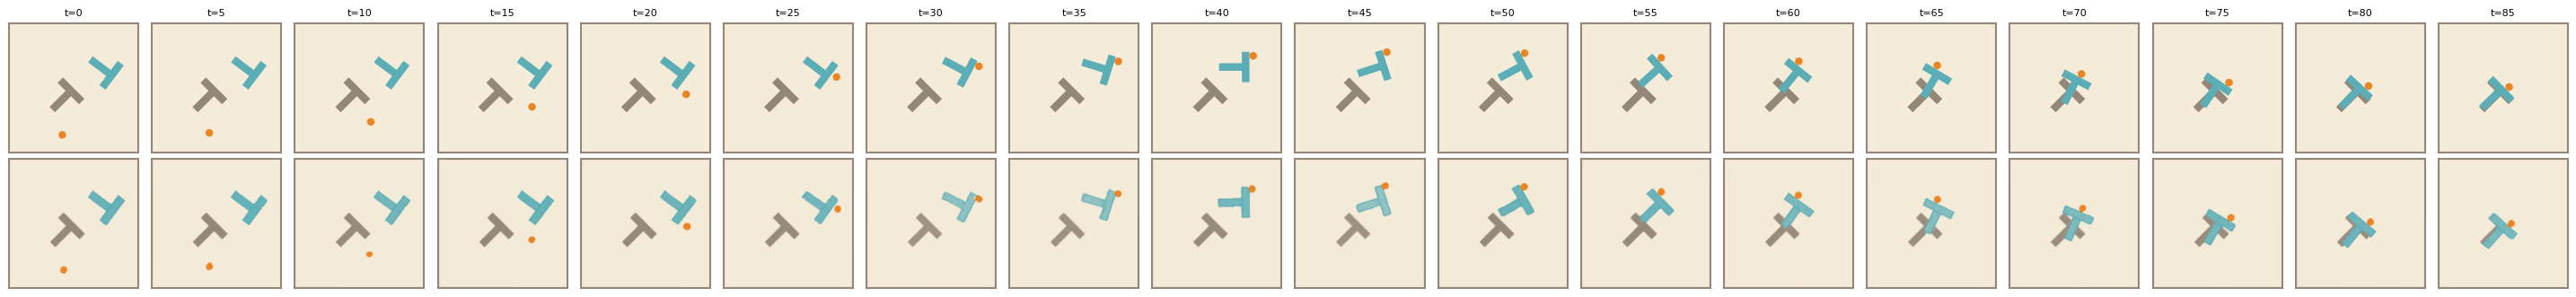

In [9]:
assert ROLLOUT_STRIDE % 5 == 0, "ROLLOUT_STRIDE must be a multiple of the 5-step action block"
n_blocks = ep_len // 5
n_steps  = n_blocks * 5                  # truncate the tail so real and WM cover the same span

# ── real env rollout: record state after every step ────────────────────────
env_play.reset(seed=0)
env_play.unwrapped._set_state(state=init_state)
real_states = [env_play.unwrapped._get_obs()]
for t in range(n_steps):
    obs, _, term, trunc, _ = env_play.step(actions_env[t])
    real_states.append(env_play.unwrapped._get_obs())
    if term or trunc:
        print(f"env ended early at t={t+1}"); break
real_states = np.stack(real_states)      # (n_steps+1, 7)

# ── world-model rollout: one predicted embedding per 5-step block ──────────
wm_embs   = imagine(first_emb, [actions_env[k*5:(k+1)*5] for k in range(n_blocks)])
wm_frames = {0: start_decoded if WM_T0 == "decoded" else start_state_real}
for k, emb in enumerate(wm_embs[1:], start=1):
    wm_frames[k * 5] = decode_recolored(emb)

# ── pick the frames to show ────────────────────────────────────────────────
steps = list(range(0, len(real_states), ROLLOUT_STRIDE))
steps = [s for s in steps if s in wm_frames]
if MAX_FRAMES is not None:
    steps = steps[:MAX_FRAMES]
print(f"{len(steps)} frames at steps {steps}")

fig, axs = plt.subplots(2, len(steps), figsize=(1.6 * len(steps), 3.4))
for j, s in enumerate(steps):
    render_state(real_states[s], axs[0, j]); axs[0, j].set_title(f"t={s}", fontsize=8)
    render_item(wm_frames[s], axs[1, j])
axs[0, 0].set_ylabel("real"); axs[1, 0].set_ylabel("world model")
plt.tight_layout(); plt.show()

np.savez(OUT_DIR / "rollout_data.npz",
         real_states=real_states, actions=actions_env[:n_steps], steps=np.array(steps),
         wm_embeddings=np.stack([e.cpu().numpy().ravel() for e in wm_embs]),
         episode_id=EPISODE_ID)


### Vertical strips → SVG
`vertical_strip` takes any list of items (states or images) and stacks them top→bottom with step labels.
Saves one SVG per strip plus a combined two-column version.

saved /home/stephen/Stephencwelch Dropbox/welch_labs/ai_book_vol_2/4_jepa/graphics/ep_18002/rollout_real_strip.svg


saved /home/stephen/Stephencwelch Dropbox/welch_labs/ai_book_vol_2/4_jepa/graphics/ep_18002/rollout_wm_strip.svg


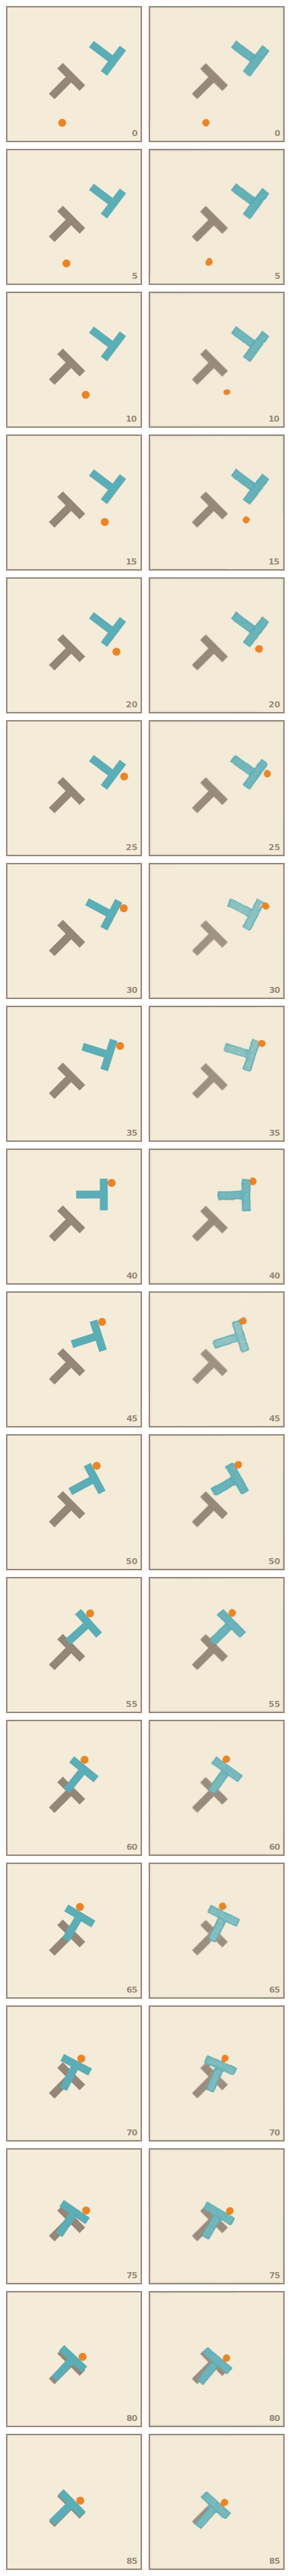

saved /home/stephen/Stephencwelch Dropbox/welch_labs/ai_book_vol_2/4_jepa/graphics/ep_18002/rollout_real_vs_wm.svg


In [10]:
STRIP_FRAME_SIZE = 2.0      # inches per frame
STRIP_GAP        = 0.12     # inches between frames (vertical, and between columns in the combined file)

def vertical_strip(items, steps, path, frame_size=STRIP_FRAME_SIZE, gap=STRIP_GAP, show=False):
    n = len(items); g = gap / frame_size
    fig = plt.figure(figsize=(frame_size, n * frame_size + (n - 1) * gap))
    fig.patch.set_alpha(0)
    for i, (item, t) in enumerate(zip(items, steps)):
        ax = fig.add_axes([0, (n - 1 - i) * (1 + g) / (n + (n - 1) * g), 1, 1 / (n + (n - 1) * g)])
        render_item(item, ax); add_step_label(ax, t)
    fig.savefig(path, transparent=True, bbox_inches="tight", pad_inches=0.02)
    if show: plt.show()
    else: plt.close(fig)
    print("saved", path)

def vertical_strips(columns, steps, path, frame_size=STRIP_FRAME_SIZE, gap=STRIP_GAP, show=True):
    """columns: list of item-lists, drawn side by side."""
    n, m = len(steps), len(columns); g = gap / frame_size
    fig = plt.figure(figsize=(m * frame_size + (m - 1) * gap, n * frame_size + (n - 1) * gap))
    fig.patch.set_alpha(0)
    for c, items in enumerate(columns):
        for i, (item, t) in enumerate(zip(items, steps)):
            ax = fig.add_axes([c * (1 + g) / (m + (m - 1) * g), (n - 1 - i) * (1 + g) / (n + (n - 1) * g),
                               1 / (m + (m - 1) * g), 1 / (n + (n - 1) * g)])
            render_item(item, ax); add_step_label(ax, t)
    fig.savefig(path, transparent=True, bbox_inches="tight", pad_inches=0.02)
    if show: plt.show()
    else: plt.close(fig)
    print("saved", path)

real_items = [real_states[s] for s in steps]
wm_items   = [wm_frames[s]   for s in steps]

vertical_strip (real_items,             steps, OUT_DIR / "rollout_real_strip.svg")
vertical_strip (wm_items,               steps, OUT_DIR / "rollout_wm_strip.svg")
vertical_strips([real_items, wm_items], steps, OUT_DIR / "rollout_real_vs_wm.svg")


## Scratch

In [ ]:
# ── Batch: real-vs-WM strips for many random episodes ──────────────────────
from tqdm import tqdm

BATCH_SEED   = 25            # same shuffle as p69_73 → same episode set
BATCH_N      = 100
BATCH_START  = 0             # resume from here if interrupted
BATCH_ROOT   = OUT_ROOT / "batch"
BATCH_PNG    = True          # also write a quick PNG preview per episode (fast to flip through)

def rollout_episode(ep_id):
    """Real + WM rollouts for one episode → (real_items, wm_items, steps)."""
    ep_len = int(ep_lens[ep_id]); row0 = int(ep_starts[ep_id])
    acts = np.stack([ds[row0 + t]["action"].squeeze(0).cpu().numpy() for t in range(ep_len)]).astype(np.float32)
    s0   = ds[row0]["state"].squeeze(0).cpu().numpy().astype(np.float32)
    n_blocks = ep_len // 5; n_steps = n_blocks * 5

    env = gym.make("swm/PushT-v1", render_mode="rgb_array", max_episode_steps=ep_len + 10)
    env.reset(seed=0); env.unwrapped._set_state(state=s0)
    frame0 = env.render(); state0 = env.unwrapped._get_obs()
    emb0   = encode_frame(frame0)

    states = [state0]
    for t in range(n_steps):
        _, _, term, trunc, _ = env.step(acts[t])
        states.append(env.unwrapped._get_obs())
        if term or trunc: break
    env.close()
    states = np.stack(states)

    embs = imagine(emb0, [acts[k*5:(k+1)*5] for k in range(n_blocks)])
    wm = {0: decode_recolored(emb0) if WM_T0 == "decoded" else state0}
    for k, e in enumerate(embs[1:], start=1):
        wm[k * 5] = decode_recolored(e)

    steps = [s for s in range(0, len(states), ROLLOUT_STRIDE) if s in wm]
    if MAX_FRAMES is not None: steps = steps[:MAX_FRAMES]
    return [states[s] for s in steps], [wm[s] for s in steps], steps

np.random.seed(BATCH_SEED)
rI = np.arange(len(ep_lens)); np.random.shuffle(rI)

for count in tqdm(range(BATCH_START, BATCH_N)):
    ep_id  = int(rI[count])
    ep_dir = BATCH_ROOT / f"{count:03d}_ep_{ep_id:05d}"
    ep_dir.mkdir(parents=True, exist_ok=True)
    try:
        real_items, wm_items, steps = rollout_episode(ep_id)
        vertical_strips([real_items, wm_items], steps, ep_dir / "rollout_real_vs_wm.svg", show=False)
        if BATCH_PNG:
            n = len(steps)
            fig, axs = plt.subplots(2, n, figsize=(1.2 * n, 2.6))
            for j, s in enumerate(steps):
                render_item(real_items[j], axs[0, j]); render_item(wm_items[j], axs[1, j])
                axs[0, j].set_title(str(s), fontsize=7)
            fig.savefig(ep_dir / "preview.png", dpi=100, bbox_inches="tight", facecolor="white")
            plt.close(fig)
    except Exception as e:
        print(f"ep {ep_id} failed: {e}")

print("done →", BATCH_ROOT)

  1%|▍                                             | 1/100 [00:01<02:07,  1.29s/it]

saved /home/stephen/Stephencwelch Dropbox/welch_labs/jepa_2/hackin/push_t_book_2/batch/000_ep_08508/rollout_real_vs_wm.svg


  2%|▉                                             | 2/100 [00:02<01:33,  1.05it/s]

saved /home/stephen/Stephencwelch Dropbox/welch_labs/jepa_2/hackin/push_t_book_2/batch/001_ep_01483/rollout_real_vs_wm.svg


saved /home/stephen/Stephencwelch Dropbox/welch_labs/jepa_2/hackin/push_t_book_2/batch/002_ep_12149/rollout_real_vs_wm.svg


  3%|█▍                                            | 3/100 [00:03<01:52,  1.16s/it]WARNING:matplotlib.font_manager:findfont: Font family 'Helvetica' not found.


saved /home/stephen/Stephencwelch Dropbox/welch_labs/jepa_2/hackin/push_t_book_2/batch/003_ep_08216/rollout_real_vs_wm.svg


  4%|█▊                                            | 4/100 [00:05<02:13,  1.39s/it]